# W3: a generative model, and where a hedger should learn

Can a generator trained on one price history produce realistic paths, and does a hedger trained on those paths beat one trained in Black–Scholes or Heston? The market is simulated so we can test on unlimited fresh paths: a Bates reference market (Heston plus downward jumps, about one a year, mean size about −5%) calibrated to look like an equity index. Ten years of its daily closes and 30-day ATM implied volatility form the history, and every model is fitted only to it. Notebook 04 repeats this on SPX.

The generator (W3) is a GRU whose output is a four-component Gaussian mixture for the next day's return and IV change, trained by negative log-likelihood. W1 is Black–Scholes at the history's average implied volatility and W2 is Heston calibrated to the history. In each world we train a deep hedger (Buehler et al., 2019) that sees time to expiry, moneyness, implied volatility, BS delta and its current holding, and learns a correction to BS delta that minimises CVaR 95% of the hedging error after costs. It trades only the stock. All hedgers are tested on 5,000 fresh reference-market paths, rebalanced daily with 5 bp costs on the stock. A deep hedger trained on the reference market itself is the stock-only upper bound.

Errors are in price units with $S_0 = 100$, so 0.5 is 0.5% of the stock price; lower is better throughout. Classical strategies are defined in notebook 01 and Heston parameters in notebook 02.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# hedging is this project's own code, in src/hedging/
from hedging import bs, experiments, generator, hedge, worlds

pd.set_option("display.precision", 4)
# figures are saved to results/figures/
FIG = experiments.RESULTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

## 1. The history and the generator

`reference_history` simulates the ten-year history (close and 30-day ATM IV, left and middle). The generator trains for 800 epochs on the first 80% and is validated on the last 20%; the right panel shows `train_nll` and `val_nll`, and we keep the weights with the best `val_nll`.

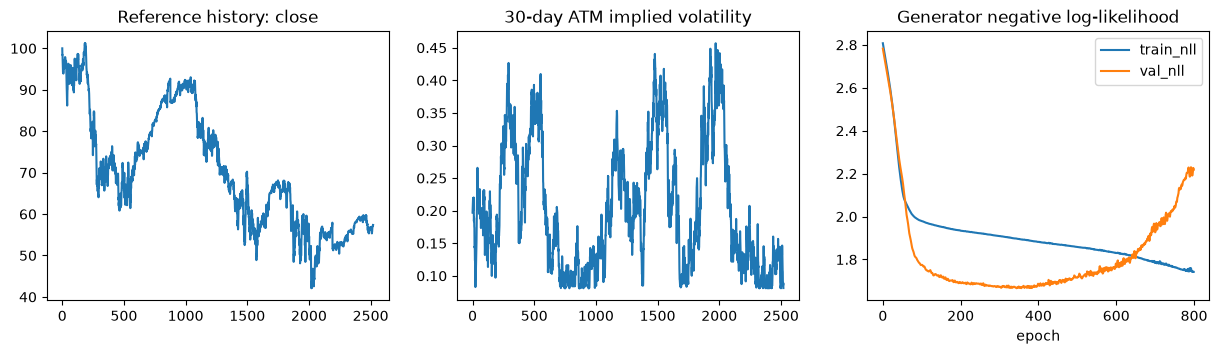

In [2]:
# ten years of daily close and 30-day ATM implied volatility from the reference market
close, atm_iv = worlds.reference_history()
# losses: training and held-out negative log-likelihood, one row per epoch
gen_model, losses = generator.fit(close, atm_iv, lr=1e-3, epochs=800)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(close); axes[0].set_title("Reference history: close")
axes[1].plot(atm_iv); axes[1].set_title("30-day ATM implied volatility")
losses.plot(ax=axes[2]); axes[2].set_title("Generator negative log-likelihood"); axes[2].set_xlabel("epoch")
fig.savefig(FIG / "w3_history.png", dpi=150, bbox_inches="tight")

Validation NLL bottoms out after a few hundred epochs and then rises while training NLL keeps falling, so the network overfits from there; keeping the best checkpoint makes the later epochs harmless.

## 2. Stylized facts

We simulate 200 one-year paths per world and compare the same statistics with the history (`results/w3_stylized_facts.csv`). The first printed line is the fitted Heston (`lam=0.0`: no jumps). `acf_abs_return_*` measures volatility clustering, `corr_return_iv_change` the leverage effect, and the `iv_*` rows the IV level, the size of its daily changes and their autocorrelation. W1 has constant volatility, so its IV rows are 0 or `NaN`.

In [3]:
# W2: Heston fitted to the history (it has no jumps)
heston_fit = worlds.calibrate_heston(close, atm_iv)
rng = np.random.default_rng(5)
# 200 paths of one year (252 trading days) from each world
S_gen, iv_gen = generator.sample(gen_model, close, atm_iv, 200, 252, seed=5)
S_h, v_h = heston_fit.simulate(100.0, heston_fit.stationary_variance(200, rng), 1.0, 252, 200, rng)
S_bs = worlds.gbm(100.0, float(atm_iv.mean()), 1.0, 252, 200, rng)
# one column per world, one row per statistic
facts = pd.DataFrame({
    "history": generator.stylized_facts(close, atm_iv),
    "W1 Black-Scholes": generator.stylized_facts(S_bs, np.full_like(S_bs, atm_iv.mean())),
    "W2 Heston (fitted)": generator.stylized_facts(S_h, np.sqrt(np.maximum(v_h, 1e-8))),
    "W3 generator": generator.stylized_facts(S_gen, iv_gen),
})
experiments.save(facts.reset_index(names="fact"), "w3_stylized_facts")
# the fitted Heston parameters
print(heston_fit)
facts

StochasticVol(kappa=2.8579269948131265, theta=0.050781576742049694, xi=0.43446646201215855, rho=-0.7299972733647629, lam=0.0, mu_j=0.0, sigma_j=0.0)


,history,W1 Black-Scholes,W2 Heston (fitted),W3 generator
vol_annual,0.2427,0.2035,0.2272,0.2416
skew,-0.8622,-0.0116,-0.1082,-0.1096
excess_kurtosis,9.2195,0.0140,2.0414,2.9957
acf_abs_return_1,0.3049,-0.0047,0.1144,0.1834
acf_abs_return_10,0.3020,-0.0093,0.0835,0.1209
corr_return_iv_change,-0.5007,NaN,-0.3646,-0.5517
iv_mean,0.2036,0.2036,0.2093,0.2119
iv_change_sd,0.0754,0.0000,0.1210,0.0728
acf_iv_change_1,0.0174,NaN,-0.1837,0.0108


W3 is closest to the history on most rows: annual volatility (0.2416 vs 0.2427), leverage (−0.5517 vs −0.5007) and daily IV change size (0.0728 vs 0.0754, where Heston gives 0.1210). It beats Heston on tails and clustering but is still far off: excess kurtosis 2.9957 (Heston 2.0414, history 9.2195) and skew −0.1096 against −0.8622. Most of the history's tail comes from the jumps, which at about one a year are too rare for the generator to learn. W1 shows none of these features, as expected.

### Five generated paths

A visual check: five one-year generator paths, price left and IV right.

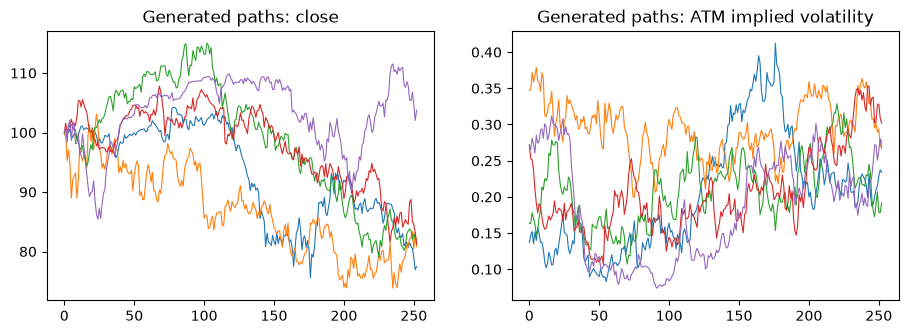

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i in range(5):
    axes[0].plot(S_gen[i], lw=.8); axes[1].plot(iv_gen[i], lw=.8)
axes[0].set_title("Generated paths: close"); axes[1].set_title("Generated paths: ATM implied volatility")
fig.savefig(FIG / "w3_generated_paths.png", dpi=150, bbox_inches="tight")

## 3. Transfer: train in one world, hedge in the test market

Deep hedgers are trained in W1, W2, W3 and the reference market (upper bound), and every strategy hedges the same 5,000 test paths daily at 5 bp (`results/w3_transfer.csv`). The first five rows are the classical strategies from notebooks 01–02; `delta_gamma` and `delta_vega` also trade a second option at 1% of its price. The bracket in `deep (...)` is the training world. A negative `mean` is mostly costs.

In [5]:
# the four training worlds, all fitted to the same history
train = experiments.training_worlds(close, atm_iv, gen_model)
# 5,000 fresh paths of the reference market
test = experiments.test_market()
# trains one deep hedger per world, then scores every strategy on the test paths
scores, errors, policies = experiments.transfer(train, test)
experiments.save(scores, "w3_transfer")
# errors: each test path's hedging error, one column per strategy (used by the bootstrap)
experiments.save(errors, "w3_test_errors")
scores

,strategy,rmse,cvar95,mean,std,turnover
0,delta,1.1777,3.9245,-0.1477,1.1684,2.3410
1,delta_gamma,0.8971,1.8742,-0.2927,0.8481,2.6574
2,delta_vega,0.8045,2.6150,-0.1530,0.7898,1.7404
3,leland,1.1721,3.9014,-0.1467,1.1628,2.3139
4,whalley_wilmott,1.1695,3.7700,-0.1134,1.1640,1.6637
5,deep (W1 Black-Scholes),1.1715,3.8459,-0.1426,1.1627,2.1814
6,deep (W2 Heston (fitted)),1.1172,3.6729,-0.1384,1.1086,2.1648
7,deep (W3 generator),1.0643,3.4142,-0.1275,1.0567,1.9997
8,deep (Reference (upper bound)),1.0551,3.1040,-0.1149,1.0488,1.7250


RMSE (left) and CVaR 95% (right); grey bars are classical strategies, green bars deep hedgers.

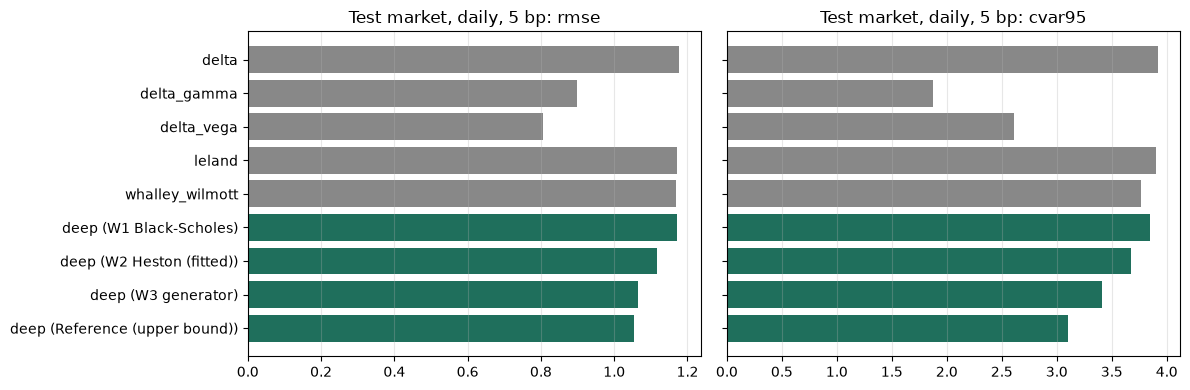

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ["rmse", "cvar95"]):
    # first five rows (textbook strategies) in grey, the four deep hedgers in green
    ax.barh(scores.strategy, scores[col], color=["#888"] * 5 + ["#1f6f5c"] * 4)
    ax.set_title(f"Test market, daily, 5 bp: {col}"); ax.grid(axis="x", alpha=.3)
axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(FIG / "w3_transfer.png", dpi=150, bbox_inches="tight")

The closer the training world is to the market, the better the hedger. RMSE goes 1.1715 (W1), 1.1172 (W2), 1.0643 (W3) against 1.0551 for the upper bound; CVaR 95% goes 3.8459, 3.6729, 3.4142 against 3.1040. W3 nearly closes the RMSE gap but not the CVaR gap, which is where its thin tails hurt. The W1 hedger is barely better than delta (1.1715 vs 1.1777), and Leland and Whalley–Wilmott are also close to delta. The option hedges still win clearly: delta–vega has the lowest RMSE (0.8045) and delta–gamma the lowest CVaR 95% (1.8742), since a stock-only hedger cannot remove volatility risk.

## 4. Paired bootstrap

All strategies share the same 5,000 test paths, so we resample paths 2,000 times and take the 2.5–97.5% range of each difference (`results/w3_bootstrap.csv`). Rows are `strategy` minus `vs`: rows 0–7 against BS delta, rows 8–10 deep hedgers against the W2-trained one. Negative means `strategy` is better; an interval containing 0 means no significant difference.

In [7]:
# each strategy minus Black-Scholes delta, then each deep hedger minus the one trained in W2
ci = pd.concat([experiments.paired_bootstrap(errors, "delta"),
                experiments.paired_bootstrap(errors[[c for c in errors if c.startswith("deep")]], "deep (W2 Heston (fitted))")],
               ignore_index=True)
experiments.save(ci, "w3_bootstrap")
ci

,strategy,vs,d_rmse,d_rmse_lo,d_rmse_hi,d_cvar95,d_cvar95_lo,d_cvar95_hi
0,delta_gamma,delta,-0.2805,-0.3694,-0.1932,-2.0503,-2.4486,-1.6588
1,delta_vega,delta,-0.3732,-0.4183,-0.3286,-1.3095,-1.4729,-1.1465
2,leland,delta,-0.0056,-0.0078,-0.0034,-0.0231,-0.0310,-0.0145
3,whalley_wilmott,delta,-0.0082,-0.0343,0.0187,-0.1545,-0.2578,-0.0451
4,deep (W1 Black-Scholes),delta,-0.0062,-0.0192,0.0071,-0.0786,-0.1285,-0.0289
5,deep (W2 Heston (fitted)),delta,-0.0605,-0.0706,-0.0501,-0.2516,-0.2939,-0.2086
6,deep (W3 generator),delta,-0.1134,-0.1417,-0.0837,-0.5103,-0.6334,-0.3938
7,deep (Reference (upper bound)),delta,-0.1226,-0.1802,-0.0633,-0.8205,-1.0694,-0.5777
8,deep (W1 Black-Scholes),deep (W2 Heston (fitted)),0.0543,0.0418,0.0666,0.1730,0.1249,0.2188
9,deep (W3 generator),deep (W2 Heston (fitted)),-0.0529,-0.0719,-0.0325,-0.2587,-0.3435,-0.1706


The ranking W3 > W2 > W1 is significant. W3 − W2 is −0.0529 in RMSE (−0.0719 to −0.0325) and −0.2587 in CVaR 95% (−0.3435 to −0.1706); W1 − W2 is +0.0543 (0.0418 to 0.0666) and +0.1730 (0.1249 to 0.2188).

Against delta, the W3 hedger gains −0.1134 in RMSE (−0.1417 to −0.0837) and −0.5103 in CVaR 95% (−0.6334 to −0.3938). The upper bound gains −0.1226 and −0.8205, so W3 captures about 92% of the possible RMSE gain but only about 62% of the CVaR gain. The W1 hedger (−0.0192 to 0.0071) and Whalley–Wilmott (−0.0343 to 0.0187) are not significantly better than delta in RMSE, though both are in CVaR 95%. Leland's RMSE gain is significant but tiny (−0.0056).

## 5. Error decomposition

We take the plain BS delta hedge and add one error source at a time: 5-minute rebalancing in W1 with no costs (nearly perfect), then daily rebalancing on the same paths, then 5 bp costs, then hedging the reference market instead of W1. W1 uses the history's average IV so the levels are comparable. Table rows are cumulative (`results/error_decomposition.csv`); in the waterfall each bar is the increment from that step.

,step,rmse,cvar95,mean,std,turnover
0,"Continuous (5-minute, W1)",0.0515,0.1177,1.2734e-05,0.0515,13.8762
1,+ Discrete (daily),0.4343,1.0109,-9.3426e-04,0.4343,2.4337
2,+ Costs,0.4575,1.1644,-1.2262e-01,0.4408,2.4337
3,+ Misspecification (test market),1.1777,3.9245,-1.4775e-01,1.1684,2.3410


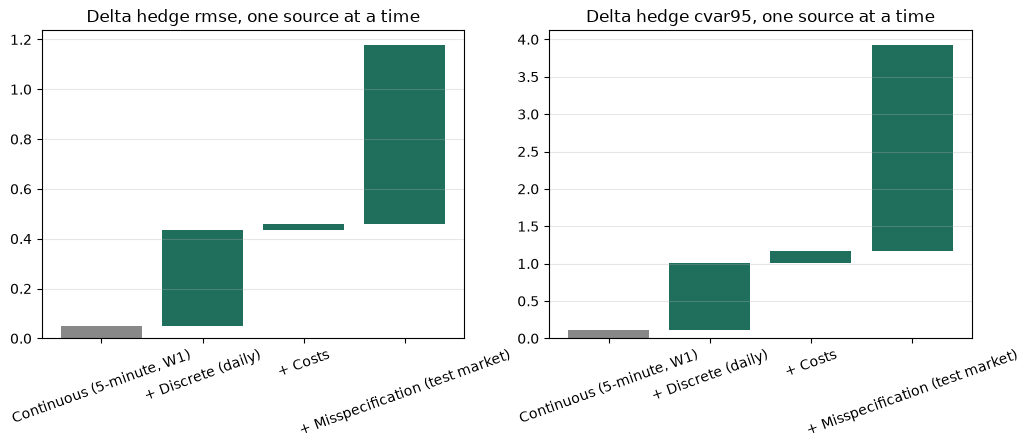

In [8]:
# W1 volatility set to the history's average implied volatility, so the levels are comparable
steps = experiments.decomposition(test, sigma=float(atm_iv.mean()))
experiments.save(steps, "error_decomposition")
display(steps)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["rmse", "cvar95"]):
    v = steps[col].to_numpy()
    # each bar starts where the previous step ended (a waterfall chart)
    bottoms = np.r_[0, v[:-1]]
    ax.bar(steps.step, v - bottoms, bottom=bottoms, color=["#888"] + ["#1f6f5c"] * (len(v) - 1))
    ax.set_title(f"Delta hedge {col}, one source at a time"); ax.tick_params(axis="x", rotation=20); ax.grid(axis="y", alpha=.3)
fig.savefig(FIG / "error_decomposition.png", dpi=150, bbox_inches="tight")

Misspecification dominates. In RMSE, daily rebalancing adds 0.38 (0.0515 to 0.4343), costs add 0.02 (to 0.4575) and misspecification adds 0.72 (to 1.1777). It more than triples CVaR 95% (1.1644 to 3.9245). Costs mainly shift the mean (−0.0009 to −0.1226) rather than widening the distribution.